## TensorFlow Playground

Prima di scrivere codice, guardiamo una rete neurale al lavoro su [playground.tensorflow.org](https://playground.tensorflow.org): a sinistra si scelgono il dataset e le feature in ingresso, al centro gli strati nascosti (_hidden layers_), a destra si vede come la rete colora il piano (ovvero cosa restituisce in output). In alto ci sono learning rate, funzione di attivazione e il tasto `Play`.

Per ogni prova premete `Play`, aspettate qualche centinaio di epoche e annotate nella cella qui sotto la **test loss** che trovate in alto a destra (sotto alla scritta "OUTPUT"):

1. Scegliete il dataset con due nuvole separate (_Gaussian_), feature solo $x_1$ e $x_2$, e togliete tutti gli strati nascosti. Questa è esattamente la regressione logistica che conosciamo: funziona?
2. Stessa configurazione, ma con il dataset _Circle_. Perché la rete non ce la fa?
3. Sempre senza strati nascosti, aggiungete le feature $x_1^2$ e $x_2^2$. Perché adesso funziona? Vi ricorda qualcosa? E se non sapessimo in anticipo quali feature servono?
4. Tornate a sole $x_1$ e $x_2$ e aggiungete uno strato nascosto, con 1, 2, 3 e 4 neuroni: qual è il minimo che risolve il cerchio? Passate il mouse sopra ogni neurone e guardate il suo disegno: che forma ha?
5. Mettete 8 neuroni e cambiate l'attivazione in Linear: cosa succede?
6. Con una rete che funziona di quelle fatte al punto 5, provate learning rate 3 e poi 0.0001: cosa notate nella curva della loss?
7. Dataset Spiral, solo x₁ e x₂: come cambia la test loss al variare di strati, neuroni, attivazione e learning rate?

In [ ]:
# test loss letta nel playground (colonna OUTPUT, sopra il grafico) dopo qualche centinaio di epoche
test_loss = {
    "1) gaussian, nessuno strato nascosto": None,
    "2) circle, nessuno strato nascosto": None,
    "3) circle, nessuno strato nascosto, + x1² e x2²": None,
    "4) circle, 1 strato da 1 neurone": None,
    "4) circle, 1 strato da 2 neuroni": None,
    "4) circle, 1 strato da 3 neuroni": None,
    "4) circle, 1 strato da 4 neuroni": None,
    "5) circle, 1 strato da 8 neuroni, attivazione Linear": None,
    "6) learning rate 3": None,
    "6) learning rate 0.0001": None,
    # 7) spiral: aggiungete una riga per ogni configurazione provata
}

for prova, loss in test_loss.items():
    print(f"{prova:55} {loss}")

------
## Deep Learning (Reti Neurali) in PyTorch

Setup dell'ambiente (importiamo le librerie necessarie e facciamo i primi check):

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import clear_output
from sklearn.datasets import make_moons, make_circles

torch.manual_seed(0)  # fissiamo il seed: tutti otteniamo gli stessi risultati
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device usato:", device)

Scriviamo alcune funzioni per i plot, così da non ripetere ogni volta lo stesso codice:
* `plot_confine` colora il piano secondo la previsione del modello, come nel playground;
* `plot_curva` disegna la curva predetta dal modello, per la regressione;
* `plot_training` aggiorna la figura durante il training: a sinistra il modello, a destra la loss.

In [ ]:
colori = ["#0E7C86", "#E8833A", "#C0392B", "#7D3C98", "#2E86C1"]  # un colore per classe

def plot_confine(model, X, y, ax=None, title=""):
    """Colora il piano secondo la previsione del modello e disegna i punti (colorati per classe vera)."""
    ax = ax or plt.gca()
    x0, x1 = X[:, 0], X[:, 1]
    gx = torch.linspace(x0.min() - 0.5, x0.max() + 0.5, 300)
    gy = torch.linspace(x1.min() - 0.5, x1.max() + 0.5, 300)
    xx, yy = torch.meshgrid(gx, gy, indexing="xy")
    griglia = torch.stack([xx.reshape(-1), yy.reshape(-1)], dim=1)
    with torch.no_grad():
        out = model(griglia)
    if out.shape[1] == 1:  # binaria: probabilità della classe 1
        P = torch.sigmoid(out).reshape(xx.shape)
        ax.contourf(xx, yy, P, levels=20, cmap="coolwarm", alpha=.6, vmin=0, vmax=1)
        ax.contour(xx, yy, P, levels=[0.5], colors="black", linewidths=2)  # il confine (p = 0.5)
    else:  # multiclasse: la classe più probabile
        k = out.shape[1]
        Z = out.argmax(dim=1).reshape(xx.shape)
        ax.contourf(xx, yy, Z, levels=torch.arange(k + 1) - 0.5, cmap=ListedColormap(colori[:k]), alpha=.3)
    for c in y.unique():
        sel = y.reshape(-1) == c
        ax.scatter(x0[sel], x1[sel], s=14, c=colori[int(c)], edgecolor="white", lw=.3, label=f"classe {int(c)}")
    ax.set_title(title)


def plot_curva(model, x, y, ax=None, x_min=None, x_max=None, title=""):
    """Regressione 1D: i punti del dataset e la curva predetta dal modello."""
    ax = ax or plt.gca()
    x_min = x.min().item() if x_min is None else x_min
    x_max = x.max().item() if x_max is None else x_max
    xs = torch.linspace(x_min, x_max, 500).unsqueeze(1)
    with torch.no_grad():
        ys = model(xs)
    ax.scatter(x, y, s=12, alpha=.5, c=colori[0])
    ax.plot(xs, ys, color="red", lw=3)
    ax.set_title(title)


def plot_training(model, X, y, storia, epoca):
    """Aggiorna la figura durante il training: a sinistra il modello, a destra la loss."""
    clear_output(wait=True)  # cancella la figura precedente: effetto "animazione"
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
    if X.shape[1] == 1:
        plot_curva(model, X, y, ax1, title=f"epoca {epoca}")
    else:
        plot_confine(model, X, y, ax1, title=f"epoca {epoca}")
    ax2.plot(storia)
    ax2.set_yscale("log")
    ax2.set_xlabel("epoche"); ax2.set_ylabel("loss"); ax2.set_title(f"loss = {storia[-1]:.4g}")
    plt.tight_layout(); plt.show()

Riprendiamo l'esempio delle lune che abbiamo usato anche per la regressione logistica:

In [ ]:
Xm, ym = make_moons(n_samples=400, noise=0.2, random_state=0)
X = torch.tensor(Xm, dtype=torch.float32)               # (N, 2)
y = torch.tensor(ym, dtype=torch.float32).unsqueeze(1)  # (N, 1): stessa forma dell'uscita del modello

Finora la regressione logistica l'abbiamo scritta a mano: `z = X @ Alpha + beta` ma PyTorch ha una funzione che fa esattamente questo, `nn.Linear`, e crea da solo i parametri da ottimizzare (ovvero quelli che vogliamo imparare):

In [ ]:
lin = nn.Linear(2, 1)  # 2 feature in ingresso, 1 uscita
print("pesi: ", lin.weight)  # Alpha
print("intercetta (bias): ", lin.bias)    # il beta

# verifichiamo che faccia proprio X @ Alpha + beta
print(torch.allclose(lin(X), X @ lin.weight.T + lin.bias))

Anche la loss ha la sua funzione: `nn.BCEWithLogitsLoss` applica la sigmoide e poi la binary cross entropy, tutto in un passo (ed è numericamente più stabile). 

Il modello restituisce direttamente `z`, che si chiama _logit_ ed è il "punteggio grezzo" che esce dalla rete prima della sigmoide: un numero qualsiasi, anche negativo, che la sigmoide trasforma in una probabilità.

Scriviamo una funzione per l'accuratezza: `z > 0` equivale a `sigmoid(z) > 0.5`.

In [ ]:
def accuratezza_binaria(model, X, y):
    with torch.no_grad():
        pred = (model(X) > 0).float()
    return (pred == y).float().mean().item()

La stessa regressione logistica del notebook precedente, scritta con le funzioni ad-hoc di PyTorch:

In [ ]:
model = nn.Linear(2, 1)
loss_fn = nn.BCEWithLogitsLoss()  # sigmoide + binary cross entropy
opt = torch.optim.SGD(model.parameters(), lr=0.1)  # model.parameters() al posto di [Alpha, beta]

storia = []
n_epoche = 300
for epoca in range(1, n_epoche + 1):
    z = model(X)
    loss = loss_fn(z, y)
    opt.zero_grad()  # 1) azzera i gradienti
    loss.backward()  # 2) calcola i gradienti
    opt.step()       # 3) fai il passo
    storia.append(loss.item())
    if epoca % 20 == 0:
        plot_training(model, X, y, storia, epoca)

print(f"Accuratezza: {accuratezza_binaria(model, X, y):.1%}")

Cosa possiamo osservare? Dove sbaglia il modello?

E con i cerchi visti all'inizio nel playground? Rifacciamo la stessa cosa:

In [ ]:
Xc, yc = make_circles(n_samples=400, noise=0.1, factor=0.4, random_state=0)
X = torch.tensor(Xc, dtype=torch.float32)
y = torch.tensor(yc, dtype=torch.float32).unsqueeze(1)

model = nn.Linear(2, 1)
opt = torch.optim.SGD(model.parameters(), lr=0.1)
storia = []
for epoca in range(1, n_epoche + 1):
    loss = loss_fn(model(X), y)
    opt.zero_grad(); loss.backward(); opt.step()
    storia.append(loss.item())
    if epoca % 20 == 0:
        plot_training(model, X, y, storia, epoca)

print(f"Accuratezza: {accuratezza_binaria(model, X, y):.1%}")

L'accuratezza si ferma intorno al 50%, come tirare a caso: un neurone solo traccia una retta, e nessuna retta per definizione può separare cerchi concentrici.

## Più neuroni connessi danno vita ad una rete

Come possiamo creare una rete neurale in PyTorch?

`nn.Linear(2, 1)` è un neurone con 2 ingressi. `nn.Linear(2, 3)` sono **tre neuroni** che guardano gli stessi 2 ingressi, ognuno con i suoi pesi e il suo bias:

![torch_linear](images/torch_linear.png)

In [ ]:
lin = nn.Linear(2, 3)
print("pesi:", lin.weight.shape)  # (3, 2): una riga di 2 pesi per ognuno dei 3 neuroni
print("bias:", lin.bias.shape)    # (3,): un bias per neurone

uscita = lin(X[:5])  # passiamo i primi 5 punti
print(X[:5].shape, "->", uscita.shape)

Ogni punto entra con 2 numeri ed esce con 3, uno per neurone dell'ultimo strato. Ogni neurone calcola `X @ w + b`, con i suoi pesi `w` (una riga di `lin.weight`) e il suo bias `b` (un elemento di `lin.bias`).

### Funzioni di attivazione

Dopo uno strato lineare si applica a ogni neurone una funzione **non lineare**, detta _funzione di attivazione_. Le più usate:

In [ ]:
x = torch.linspace(-4, 4, 200)
attivazioni = {"ReLU": nn.ReLU(), "Sigmoid": nn.Sigmoid()}

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, (nome, f) in zip(axes, attivazioni.items()):
    ax.plot(x, f(x), color=colori[0], lw=3)
    ax.axhline(0, color="black", lw=.5); ax.axvline(0, color="black", lw=.5)
    ax.set_title(nome)
plt.tight_layout(); plt.show()

La sigmoide la conosciamo già. Oggi la più usata è la **ReLU** (_Rectified Linear Unit_): lascia passare i valori positivi e mette a zero quelli negativi. È semplicissima, ma come vedremo ci permette di imparare modelli molto potenti.

In [ ]:
relu = nn.ReLU()
print(relu(torch.tensor([-2.0, -0.5, 0.0, 1.5, 3.0])))

`nn.Sequential` prende una lista di strati e li applica uno dopo l'altro: l'uscita di ognuno è l'ingresso del successivo (quindi il numero di neuroni deve essere compatibile!):

In [ ]:
model = nn.Sequential(
    nn.Linear(2, 16, bias=True),  # strato nascosto: 16 neuroni
    nn.ReLU(),         # attivazione
    nn.Linear(16, 1),  # strato di uscita: 1 neurone (il logit)
)
print(model)

Seguiamo 5 punti (presi dal dataset dei cerchi) mentre attraversano la rete:

In [ ]:
h = X[:5]
print("ingresso:", tuple(h.shape))
for strato in model:
    h = strato(h)
    print(f"dopo {strato.__class__.__name__}:", tuple(h.shape))

Tocca a voi: quanti parametri (pesi + bias) ha questa rete? Calcolatelo a mano, poi verificate:

In [ ]:
# TODO: calcolo a mano
# strato 1: ...
# strato 2: ...
print("parametri:", sum(p.numel() for p in model.parameters()))

### Componiamo un Multi-Layer Perceptron (MLP) in PyTorch

Riprendiamo il ciclo di training dei cerchi e cambiamo il modello.  

Cambiamo anche l'ottimizzatore: **Adam** (_Adaptive Moment Estimation_) è una versione più "smart" della discesa del gradiente, che adatta da sola il passo per ogni parametro e converge molto più in fretta.

In [ ]:
torch.manual_seed(0)
model = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 1),
)
loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(model.parameters(), lr=0.01)

storia = []
n_epoche = 1000
for epoca in range(1, n_epoche + 1):
    z = model(X)
    loss = loss_fn(z, y)
    opt.zero_grad()  # 1) azzera i gradienti
    loss.backward()  # 2) calcola i gradienti
    opt.step()       # 3) fai il passo
    storia.append(loss.item())
    if epoca % 50 == 0:
        plot_training(model, X, y, storia, epoca)

print(f"Accuratezza: {accuratezza_binaria(model, X, y):.1%}")

Il confine diventa una curva chiusa e l'accuratezza arriva al 100%.

**NB**: il ciclo di training è identico a prima, è cambiata solo l'architettura!

### E se togliamo la ReLU?

Tocca a voi: copiate la cella precedente e togliete (o commentate) `nn.ReLU()` dal modello, lasciando i 16 neuroni nascosti. Prima di eseguire: cosa vi aspettate?

In [ ]:
# TODO: stesso training di prima, ma senza nn.ReLU()

Questo risultato vi ricorda qualcosa?

Uno strato lineare, senza attivazione, fa sempre la stessa cosa: "moltiplica e somma". Vediamolo con un solo ingresso `x`: se il primo strato calcola `y = 2 * x + 1` e il secondo `z = 3 * y - 4`, mettendoli in fila otteniamo:

$$z = 3\,(2x + 1) - 4 = 6x - 1$$

cioè ancora una funzione lineare (retta). 

Con 16 neuroni i calcoli sono di più e più intrigati, ma il risultato non cambia: senza attivazione il confine resta una retta come nella regressione logistica.

#### Quanti neuroni servono per separare i cerchi concentrici?

Verifichiamolo provando diverse dimensioni dello strato nascosto:

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
hidden_dims = [1, 2, 3, 8]
for ax, n in zip(axes, hidden_dims):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(2, n), nn.ReLU(), nn.Linear(n, 1))
    opt = torch.optim.Adam(model.parameters(), lr=0.01)
    for epoca in range(1000):
        loss = loss_fn(model(X), y)
        opt.zero_grad(); loss.backward(); opt.step()
    acc = accuratezza_binaria(model, X, y)
    plot_confine(model, X, y, ax, title=f"{n} neuroni: accuratezza {acc:.0%}")
plt.tight_layout(); plt.show()

Come varia la forma del confine al variare del numero di neuroni? Perchè? 

**NB**: Ogni neurone vale zero da una parte di una retta e cresce dall'altra. Lo strato di uscita combina queste "rampe" e ne ricava un poligono che racchiude il cerchio interno: la rete ha **imparato da sola le feature** che le servivano, invece di aggiungerle a mano come abbiamo fatto con `hp²`.

Tocca a voi: ripetete il training dell'MLP sulle lune. Come prima cosa, raccogliamo i passi visti finora in due funzioni:

In [ ]:
def crea_mlp(hidden=[16], n_out=1):
    """MLP con 2 ingressi, gli strati nascosti indicati in hidden (es. [16, 16]) e n_out uscite."""
    strati = []
    n_in = 2
    for h in hidden:  # uno strato nascosto (Linear + ReLU) per ogni numero della lista
        strati += [nn.Linear(n_in, h), nn.ReLU()]
        n_in = h
    strati.append(nn.Linear(n_in, n_out))  # strato di uscita: i logit
    return nn.Sequential(*strati)


def train_rete(model, X, y, loss_fn, n_epoche=1000, lr=0.01):
    """Allena il modello con la loss indicata e Adam, e ritorna la storia della loss."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    storia = []
    for epoca in range(1, n_epoche + 1):
        loss = loss_fn(model(X), y)
        opt.zero_grad()  # 1) azzera i gradienti
        loss.backward()  # 2) calcola i gradienti
        opt.step()       # 3) fai il passo
        storia.append(loss.item())
    return storia

Adesso facciamo il training del modello sul dataset delle lune:

In [ ]:
Xm, ym = make_moons(n_samples=400, noise=0.2, random_state=0)
X = torch.tensor(Xm, dtype=torch.float32)
y = torch.tensor(ym, dtype=torch.float32).unsqueeze(1)

# TODO: training del modello sulle lune 
# model = 
# loss_fn = 
# storia = 

# TODO: togli il simbolo del commento quando hai definito le variabili sopra
# print(f"Accuratezza: {accuratezza_binaria(model, X, y):.1%}")
# plot_training(model, X, y, storia, epoca=1000)

Quanto guadagna l'MLP rispetto alla regressione logistica? 

Provate a cambiare `n_neuroni` (per esempio 1, 2, 4, 16, 64): cosa succede all'accuratezza e al confine?

### E se le classi possibili sono più di due? Classificazione multiclasse

Creiamo un dataset con tre spirali intrecciate, una versione più difficile della spirale del playground:

In [ ]:
def crea_spirali(n_per_classe=200, n_classi=3, rumore=0.15):
    X, y = [], []
    for c in range(n_classi):
        r = torch.linspace(0.1, 1, n_per_classe)  # distanza dal centro
        inizio = c * 2 * torch.pi / n_classi        # ogni spirale parte ruotata
        theta = torch.linspace(inizio, inizio + 3 * torch.pi, n_per_classe) + rumore * torch.randn(n_per_classe)
        X.append(torch.stack([r * torch.cos(theta), r * torch.sin(theta)], dim=1))
        y.append(torch.full((n_per_classe,), c))   # etichetta della classe: 0, 1 o 2
    return torch.cat(X), torch.cat(y)

torch.manual_seed(0)
X, y = crea_spirali()
print(X.shape, y.shape, y.dtype)  # y: interi (long), forma (N,)

for c in range(3):
    plt.scatter(X[y == c, 0], X[y == c, 1], s=14, c=colori[c], label=f"classe {c}")
plt.legend(); plt.gca().set_aspect("equal"); plt.show()

Le classi sono rappresentate con un **encoding intero** (0, 1, 2): PyTorch si occupa da solo di confrontarlo con l'uscita della rete.

Cosa cambia rispetto al caso binario:

| | Binaria | Multiclasse (k classi) |
| --- | --- | --- |
| Neuroni di uscita | 1 | k, uno per classe |
| Cosa esce dalla rete | un logit | k logit, un "punteggio" per classe |
| Da logit a probabilità | sigmoide | softmax |
| Loss | `nn.BCEWithLogitsLoss` | `nn.CrossEntropyLoss` |
| Classe predetta | logit > 0 | indice del logit più grande (`argmax`) |

Come `BCEWithLogitsLoss` contiene la sigmoide, `CrossEntropyLoss` contiene già la softmax: la rete restituisce i logit "grezzi".

### Cos'è la softmax?

La rete restituisce un punteggio (_logit_) per ogni classe: numeri qualsiasi, anche negativi. La softmax li trasforma in probabilità in due passi:
1. applica l'esponenziale a ogni punteggio: così diventano tutti positivi, e un punteggio più alto diventa *molto* più grande;
2. divide ognuno per la somma di tutti: così le probabilità sommano a 1.

![softmax](images/softmax.png)
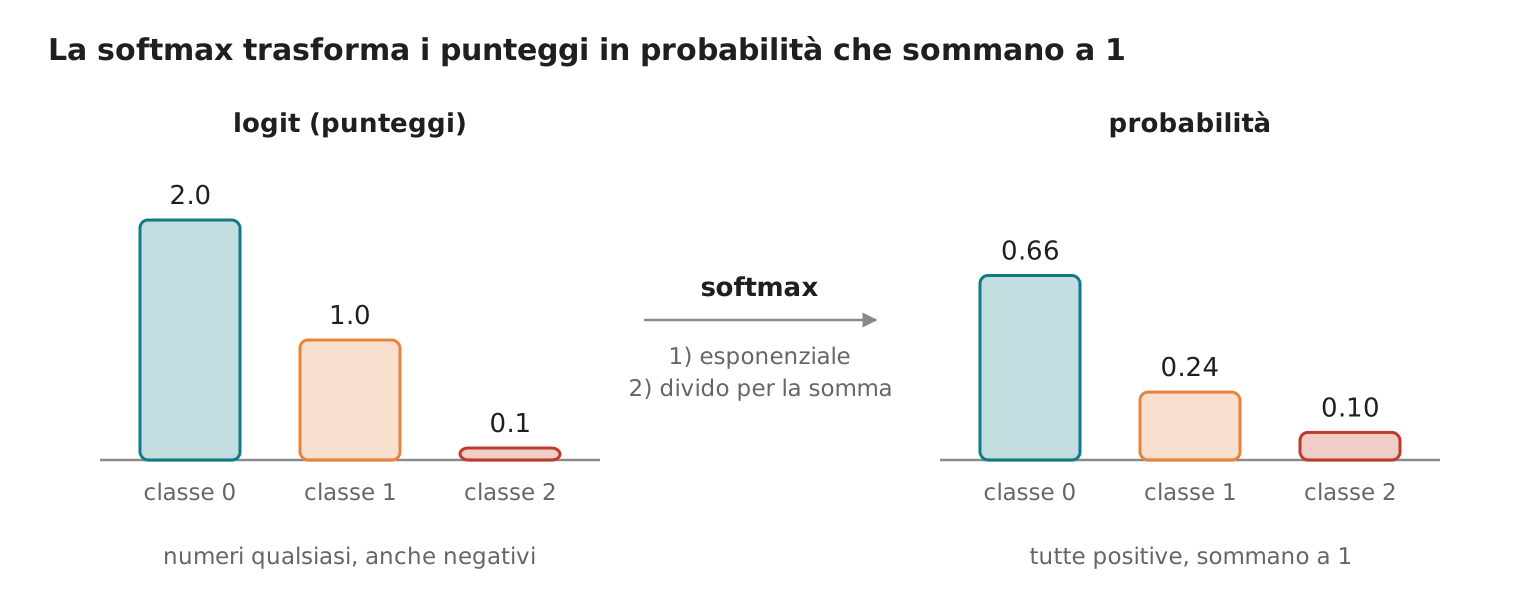

In [ ]:
logits = torch.tensor([2.0, 1.0, 0.1])
prob = torch.softmax(logits, dim=0)
print(prob)        # circa [0.66, 0.24, 0.10]
print(prob.sum())  # 1

In [ ]:
def accuratezza_multiclasse(model, X, y):
    with torch.no_grad():
        pred = model(X).argmax(dim=1)  # per ogni punto, la classe con il punteggio più alto
    return (pred == y).float().mean().item()

Quando si costruisce una rete neurale per la classificazione multiclasse lo strato di output deve avere tanti neuroni quanti sono i possibili valori della variabile categorica che vogliamo predire:

In [ ]:
torch.manual_seed(0)
model = nn.Sequential(
    nn.Linear(2, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, 3),  # 3 uscite: una per spirale
)
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=0.01)

storia = []
n_epoche = 2000
for epoca in range(1, n_epoche + 1):
    loss = loss_fn(model(X), y)
    opt.zero_grad(); loss.backward(); opt.step()
    storia.append(loss.item())
    if epoca % 100 == 0:
        plot_training(model, X, y, storia, epoca)

print(f"Accuratezza: {accuratezza_multiclasse(model, X, y):.1%}")

Tocca a voi: proviamo diverse architetture e raccogliamo i risultati in una tabella. Riutilizziamo `crea_mlp` e `train_rete`, definite per le lune: basta chiedere 3 uscite e usare la `CrossEntropyLoss`. La funzione `prova_architettura` crea la rete con gli strati nascosti indicati (per esempio `[16, 16]` sono due strati da 16 neuroni) e restituisce numero di parametri e accuratezza:

In [ ]:
import pandas as pd

def prova_architettura(hidden, seed=0, n_epoche=2000, lr=0.01):
    """Allena sulle spirali una rete con gli strati nascosti indicati e ritorna (numero di parametri, accuratezza)."""
    torch.manual_seed(seed)
    model = crea_mlp(hidden, n_out=3)  # 3 uscite: una per spirale
    train_rete(model, X, y, nn.CrossEntropyLoss(), n_epoche=n_epoche, lr=lr)
    n_parametri = sum(p.numel() for p in model.parameters())
    return n_parametri, accuratezza_multiclasse(model, X, y)

I risultati li raccogliamo in un `DataFrame`: ogni chiamata ad `aggiungi_riga` allena una rete e aggiunge una riga alla tabella.

In [ ]:
risultati = pd.DataFrame(columns=["# strati nascosti", "seed", "parametri", "accuratezza"])

def aggiungi_riga(hidden, seed=0):
    n_parametri, acc = prova_architettura(hidden, seed)
    risultati.loc[len(risultati)] = [str(hidden), seed, n_parametri, round(acc, 3)]
    return risultati

In [ ]:
aggiungi_riga([])  # nessuno strato nascosto: regressione logistica multiclasse

In [ ]:
aggiungi_riga([4])  # uno strato da 4 neuroni

In [ ]:
# TODO: aggiungete le righe per uno strato da 16, due strati da 16 e uno strato da 64

Che relazione vedete tra numero di parametri e accuratezza? 

#### E per la regressione?

La stessa rete può predire un numero invece di una classe. 

Creiamo dei dati che seguono una curva ondulata, con un po' di oscillazioni:

In [ ]:
torch.manual_seed(0)
x = torch.linspace(-3, 3, 200).unsqueeze(1)  # (200, 1): una sola feature
y = torch.sin(2 * x) + 0.3 * x + 0.1 * torch.randn_like(x)

plt.scatter(x, y, s=12, alpha=.6, c=colori[0])
plt.show()

Per la regressione l'uscita è un solo neurone **senza attivazione** (il valore da predire può essere qualsiasi numero) e la loss è il solito MSE, che in PyTorch è `nn.MSELoss`.

Partiamo dalla regressione lineare, scritta in PyTorch con `nn.Linear`:

In [ ]:
torch.manual_seed(0)
model = nn.Linear(1, 1)
loss_fn = nn.MSELoss()
opt = torch.optim.Adam(model.parameters(), lr=0.01)

storia = []
n_epoche = 2000
for epoca in range(1, n_epoche + 1):
    loss = loss_fn(model(x), y)
    opt.zero_grad(); loss.backward(); opt.step()
    storia.append(loss.item())
    if epoca % 200 == 0:
        plot_training(model, x, y, storia, epoca)

Aggiungiamo una funzione di attivazione (`nn.ReLU` che abbiamo usato anche prima):

In [ ]:
torch.manual_seed(0)
model = nn.Sequential(nn.Linear(1, 5), nn.ReLU(), nn.Linear(5, 1))
opt = torch.optim.Adam(model.parameters(), lr=0.01)

storia = []
for epoca in range(1, n_epoche + 1):
    loss = loss_fn(model(x), y)
    opt.zero_grad(); loss.backward(); opt.step()
    storia.append(loss.item())
    if epoca % 100 == 0:
        plot_training(model, x, y, storia, epoca)

La curva rossa è fatta di **segmenti**: ogni neurone ReLU è una "rampa" che parte da un certo punto, e la rete somma le rampe. Ogni neurone può quindi aggiungere al massimo un "gomito" alla spezzata.

Modifichiamo il modello cambiando il numero di neuroni (come prima per la rete di classificazione) e vediamo come cambia: 

In [ ]:
# model = nn.Sequential(# TODO)
opt = torch.optim.Adam(model.parameters(), lr=0.01)

storia = []
for epoca in range(1, n_epoche + 1):
    loss = loss_fn(model(x), y)
    opt.zero_grad(); loss.backward(); opt.step()
    storia.append(loss.item())
    if epoca % 100 == 0:
        plot_training(model, x, y, storia, epoca)

### Cosa succede fuori dai dati?

Alleniamo una rete grande, che segue molto bene i dati, e guardiamo cosa predice tra −6 e 6, dove non ha mai visto un punto:

In [ ]:
torch.manual_seed(0)
model = nn.Sequential(nn.Linear(1, 50), nn.ReLU(), nn.Linear(50, 1))
opt = torch.optim.Adam(model.parameters(), lr=0.01)
for epoca in range(n_epoche):
    loss = loss_fn(model(x), y)
    opt.zero_grad(); loss.backward(); opt.step()

plot_curva(model, x, y, x_min=-6, x_max=6)
plt.axvspan(-3, 3, alpha=.1, color="green")  # la zona in cui ci sono i dati
plt.show()

Fuori dalla zona verde la rete prosegue con due rette: perché proprio rette, guardando come è fatta una ReLU? Cosa ci insegna questo sull'uso di una rete per fare previsioni lontano dai dati di training?

**Esercizio**: torniamo al consumo delle auto. Nel notebook precedente abbiamo aggiunto a mano la feature `hp²` per descrivere meglio la relazione tra potenza e consumo. Allenate un MLP che parta solo da `hp` (usando le funzioni viste sopra e modificando solo dove necessario): riesce a trovare da solo una curva altrettanto buona?

In [ ]:
import pandas as pd

dfm = pd.read_csv("data/mpg.csv").dropna()
hp = torch.tensor(dfm["horsepower"].to_numpy(), dtype=torch.float32)
x_mpg = ((hp - hp.mean()) / hp.std()).unsqueeze(1)  # standardizzata, forma (N, 1)
y_mpg = torch.tensor(dfm["mpg"].to_numpy(), dtype=torch.float32).unsqueeze(1)
# TODO: MLP con 1 ingresso e 1 uscita, MSELoss, training
# TODO: plot_curva(model, x_mpg, y_mpg) e confronto della loss con il modello con hp²